In [1]:
import matplotlib.pyplot as plot
import numpy as np
import pandas as pd

data_directory = '../../data/lottery/merged/'

school_ids = pd.read_csv( f'{data_directory}/sfusd-school-id-mapping.csv' )
program_codes = pd.read_csv( f'{data_directory}/sfusd-program-code-mapping.csv' )
lottery_stats = pd.read_csv( f'{data_directory}/sfusd-lottery-all.csv' )

In [10]:
school_names = [
    'Clarendon ES',
    'Flynn (Leonard R) ES',
    'Parks (Rosa) ES',
    'Sutro ES',
]

summary_df = school_ids \
    [school_ids.school_name.isin(school_names)] \
    .merge(
        lottery_stats,
        how='left',
        on='school_id',
    ) \
    .merge(
        program_codes,
        how='left',
        on=[ 'school_id', 'program_code', 'ay' ]
    ) \
    .assign(
        choice = lambda _df: np.where( _df.choice_min <= 5, _df.choice_min, '6+' )
    ) \
    [['school_name','grade','program_code','ay','choice','num_requests']] \
    .assign(
        num_requests = lambda _df: np.where( _df.num_requests == 'nan', 0, _df.num_requests ).astype( float )
    ) \
    .groupby( ['school_name','grade','program_code','ay','choice'], as_index = False ) \
    .sum() \
    .sort_values( ['school_name','grade','program_code','ay','choice'] )

summary_df.to_csv( 'flynn-parks-sutro-lottery-summary.csv', index = False )

/var/folders/lr/v7klkd8j671bd11k9l_nvwcm0000gn/T/ipykernel_35295/1365420176.py:71: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  _axes.set_xticklabels( xticklabels, rotation = 30 )
/var/folders/lr/v7klkd8j671bd11k9l_nvwcm0000gn/T/ipykernel_35295/1365420176.py:71: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  _axes.set_xticklabels( xticklabels, rotation = 30 )
/var/folders/lr/v7klkd8j671bd11k9l_nvwcm0000gn/T/ipykernel_35295/1365420176.py:71: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  _axes.set_xticklabels( xticklabels, rotation = 30 )


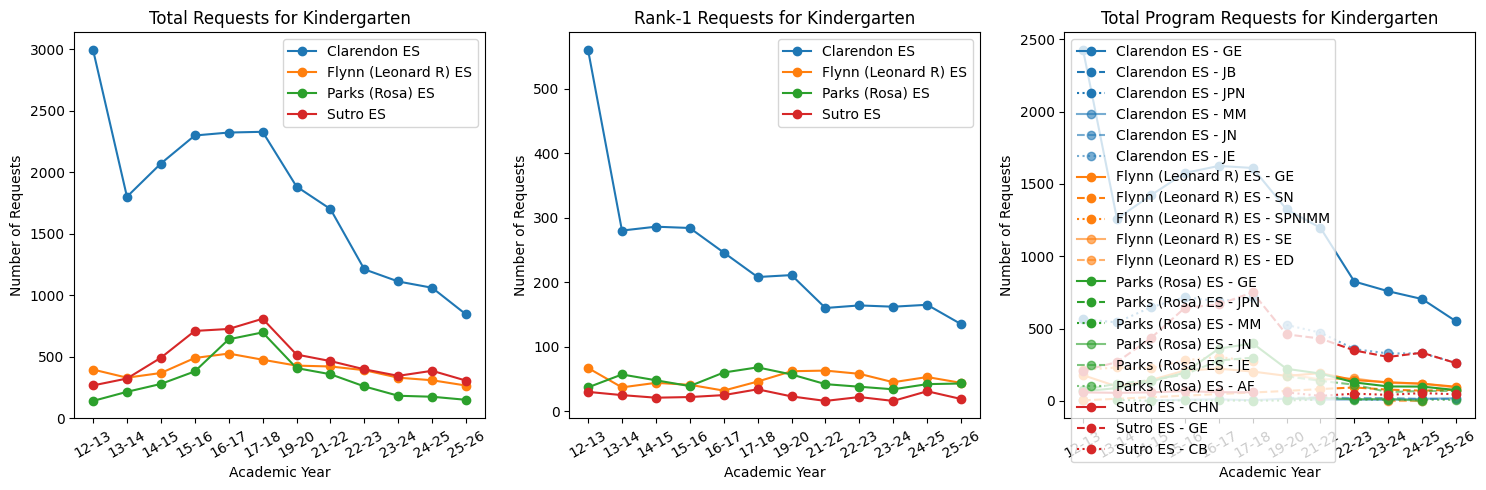

In [11]:
plot_grade = 'K'
plot_grade_label = 'Kindergarten' if plot_grade == 'K' else f'{plot_grade}th Grade'

figure, axes = plot.subplots( 1, 3, figsize = ( 15, 5 ) )

for school_name, plot_df in summary_df.groupby( 'school_name' ):
    plot_all = plot_df \
        [plot_df.grade == plot_grade] \
        [['ay','num_requests']] \
        .groupby( 'ay', as_index = False ) \
        .sum() \
        .sort_values( 'ay' )
    
    patch = axes[0].plot(
        plot_all.ay,
        plot_all.num_requests,
        marker = 'o',
        label = school_name
    )

    plot_rank_1 = plot_df \
        [ ( plot_df.grade == plot_grade ) & ( plot_df.choice == '1' ) ] \
        [['ay','num_requests']] \
        .groupby( 'ay', as_index = False ) \
        .sum() \
        .sort_values( 'ay' )
    
    axes[1].plot(
        plot_rank_1.ay,
        plot_rank_1.num_requests,
        marker = 'o',
        label = school_name,
        color = patch[0].get_color()
    )

    plot_by_program = plot_df \
        [plot_df.grade == plot_grade] \
        [['ay','program_code','num_requests']] \
        .groupby( ['ay','program_code'], as_index = False ) \
        .sum() \
        .sort_values( ['ay'] )
    for ix, program_code in enumerate(plot_by_program.program_code.unique()):
        linestyle = [ 'solid', 'dashed', 'dotted', 'dashdot' ][ix % 3]
        opacity = [ 1.0, 0.6, 0.3 ][ix // 3]
        plot_program = plot_by_program \
            [plot_by_program.program_code == program_code] \
            [['ay','num_requests']]
        axes[2].plot(
            plot_program.ay,
            plot_program.num_requests,
            marker = 'o',
            label = f'{school_name} - {program_code}',
            linestyle = linestyle,
            alpha = opacity,
            color = patch[0].get_color()
        )



axes[0].set_title( f'Total Requests for {plot_grade_label}' )
axes[1].set_title( f'Rank-1 Requests for {plot_grade_label}' )
axes[2].set_title( f'Total Program Requests for {plot_grade_label}' )
plot.draw()

for _axes in axes:
    _axes.set_xlabel( 'Academic Year' )
    _axes.set_ylabel( 'Number of Requests' )
    _axes.legend( loc = 'best' )

    xticklabels = _axes.get_xticklabels()
    _axes.set_xticklabels( xticklabels, rotation = 30 )

plot.tight_layout()
plot.show()

In [12]:
summary_df.program_code.unique()

array(['GE', 'JB', 'JPN', 'MM', 'JE', 'JN', 'ED', 'SE', 'SN', 'SPNIMM',
       'AF', 'CB', 'CHN'], dtype=object)

Available program codes at Parks (Rosa) ES: ['JPN' 'JN' 'JE']
v--- by year ---v


,ay,program_code
0,12-13,[JPN]
1,13-14,[JPN]
2,14-15,[JPN]
3,15-16,[JPN]
4,16-17,[JPN]
5,17-18,[JPN]
6,19-20,"[JE, JN]"
7,21-22,"[JE, JN]"
8,22-23,"[JE, JN]"
9,23-24,"[JE, JN]"


Available program codes at Clarendon ES: ['JPN' 'JB' 'JE' 'JN']
v--- by year ---v


,ay,program_code
0,12-13,"[JB, JPN]"
1,13-14,[JPN]
2,14-15,[JPN]
3,15-16,[JPN]
4,16-17,[JPN]
5,17-18,[JPN]
6,19-20,"[JE, JN]"
7,21-22,"[JE, JN]"
8,22-23,"[JE, JN]"
9,23-24,"[JE, JN]"


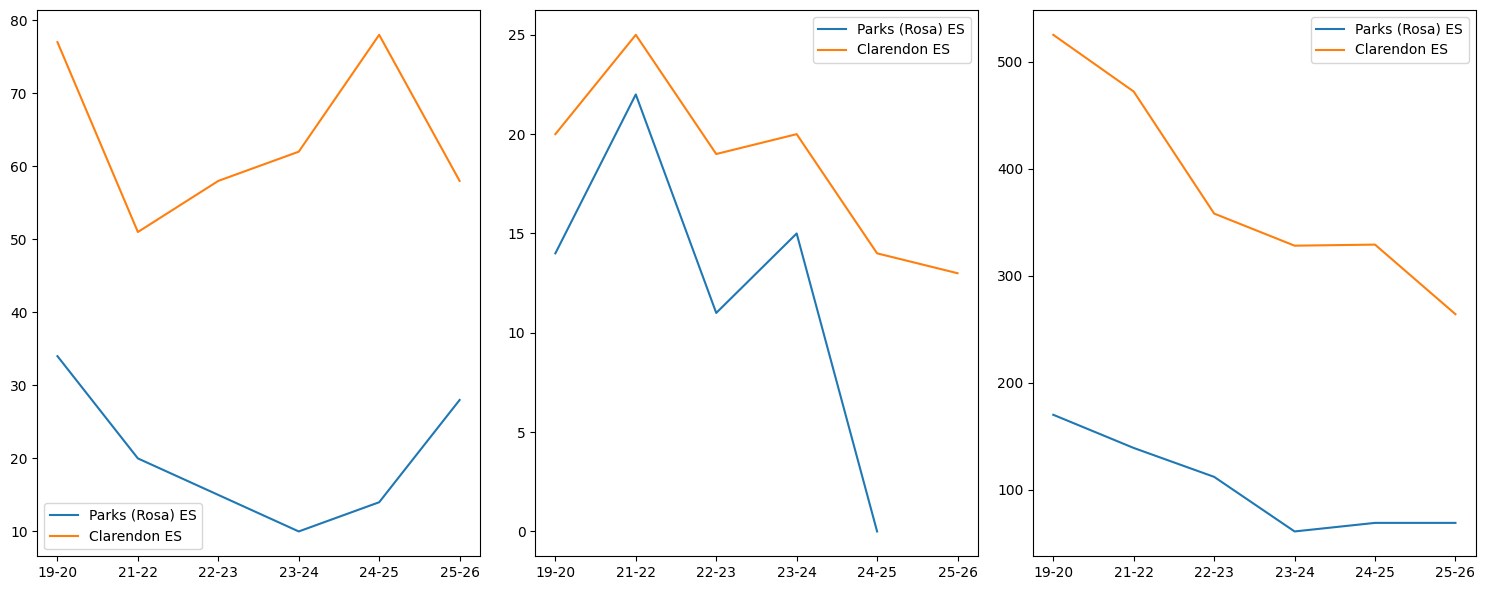

In [31]:
#
# Rosa Parks stats
#
figure, axes = plot.subplots( 1, 3, figsize = ( 15, 6 ) )

for school_name in [ 'Parks', 'Clar' ]:
    plot_df = summary_df \
        [lambda _df: _df['school_name'].str.contains( school_name )] \
        [lambda _df: _df['grade'] == 'K'] \
        .sort_values( 'ay' ) \
        .reset_index( drop = True ) \
        [lambda _df: _df['program_code'].str.lower().str.contains( 'j' )]
    
    print( f"""
Available program codes at {plot_df['school_name'].iloc[0]}: {plot_df.program_code.unique()}
v--- by year ---v
""".strip() )
    display( plot_df[['program_code','ay']].drop_duplicates().groupby( 'ay', as_index = False ).agg( lambda _: sorted( list( _ ) ) ) )
    
    series_df = plot_df \
        [lambda _df: _df['choice'] == '1'] \
        [lambda _df: _df['program_code'] == 'JE']
    axes[0].plot( series_df['ay'], series_df['num_requests'], label = plot_df['school_name'].iloc[0] )

    series_df = plot_df \
        [lambda _df: _df['program_code'] == 'JN'] \
        .groupby( 'ay', as_index = False ) \
        ['num_requests'] \
        .sum()
    axes[1].plot( series_df['ay'], series_df['num_requests'], label = plot_df['school_name'].iloc[0] )

    series_df = plot_df \
        [lambda _df: _df['program_code'] == 'JE'] \
        .groupby( 'ay', as_index = False ) \
        ['num_requests'] \
        .sum()
    axes[2].plot( series_df['ay'], series_df['num_requests'], label = plot_df['school_name'].iloc[0] )

#
# Clean-up plot
#
### THIS ADDED NOTHING, because the JPN and JB program codes are temporally segregated
#
# for school_name in [ 'Parks', 'Clar' ]:
#     plot_df = summary_df \
#         [lambda _df: _df['school_name'].str.contains( school_name )] \
#         [lambda _df: _df['grade'] == 'K'] \
#         .sort_values( 'ay' ) \
#         .reset_index( drop = True ) \
#         [lambda _df: _df['program_code'].str.lower().str.contains( 'j' )]
    
#     series_df = plot_df \
#         [lambda _df: _df['program_code'].isin( [ 'JB', 'JPN' ] )] \
#         .groupby( 'ay', as_index = False ) \
#         ['num_requests'] \
#         .sum()
#     axes[1].plot( series_df['ay'], series_df['num_requests'], label = plot_df['school_name'].iloc[0] + ' (addl)' )

for ax in axes:
    ax.legend( loc = 'best' )

plot.tight_layout()
plot.show()

In [35]:
#
# Figure out the standard share of JE/JN
#
ols_df = summary_df \
    [lambda _df: _df['school_name'] == 'Parks (Rosa) ES'] \
    [lambda _df: _df['grade'] == 'K'] \
    [lambda _df: _df['program_code'].isin( [ 'JE', 'JN' ] )] \
    [lambda _df: _df['choice'] == '1'] \
    .pivot( index = 'ay', columns = 'program_code', values = 'num_requests' ) \
    .fillna( 0 ) \
    .reset_index() \
    [lambda _df: _df['JN'] > 0]

ols_df

program_code,ay,JE,JN
0,19-20,34.0,6.0
1,21-22,20.0,3.0
2,22-23,15.0,3.0
3,23-24,10.0,4.0
